# Task 4 (Medium) – Trend Analysis by Release Year
**Internship Program:** Data Analysis Using Python | Auspify Technologies  
**Project:** Netflix Content Analytics & Business Intelligence  
**Notebook File:** `Task_4_Release_Year_Trend_Analysis.ipynb`  
**Author:** Data Analysis Intern  

---

## 1. Task Objective & Analytical Scope
The objective of **Task 4** is to investigate how Netflix's content catalog has evolved historically over time. By tracking content volume across original release years and cross-examining addition dates, we identify critical inflections, production surges, format pivots (Movies vs. TV Shows), and pandemic-induced disruptions.

### Prescribed Task Workflow (from Internship Specification):
- **Step 1:** Organize and validate content by release year, distinguishing `release_year` from `year_added`.
- **Step 2:** Calculate yearly content releases across both total titles and format types.
- **Step 3:** Identify historical growth phases, peak volume years, and post-peak shifts.
- **Step 4:** Create high-clarity time series and trend visualizations.
- **Step 5:** Interpret strategic business patterns and catalog lifecycle mechanics.

## 2. Environment Setup & Upstream Data Preparation (Cumulative from Tasks 1, 2 & 3)
As required, this notebook runs completely independently in a fresh kernel. It contains the path resolver and loads the verified cleaned data produced in Task 1, with a self-contained cleaning fallback if needed.

In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling setup
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

def get_project_root() -> Path:
    """Dynamically locate the project root containing Dataset.csv."""
    current = Path.cwd()
    for candidate in [current] + list(current.parents):
        if (candidate / 'Dataset.csv').exists():
            return candidate
    return current

PROJECT_ROOT = get_project_root()
RAW_DATA_PATH = PROJECT_ROOT / 'Dataset.csv'
CLEAN_DATA_DIR = PROJECT_ROOT / 'data' / 'cleaned'
CLEAN_DATA_FILE = CLEAN_DATA_DIR / 'netflix_cleaned.csv'
OUTPUT_DIR = PROJECT_ROOT / 'outputs' / 'task_4'

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_DATA_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Clean data target: {CLEAN_DATA_FILE}")
print(f"Output directory: {OUTPUT_DIR}")

Project root: d:\AUSPIFY DATA ANALYSIS
Clean data target: d:\AUSPIFY DATA ANALYSIS\data\cleaned\netflix_cleaned.csv
Output directory: d:\AUSPIFY DATA ANALYSIS\outputs\task_4


### Upstream Data Ingestion & Fallback Pipeline
We load `netflix_cleaned.csv`. If absent, we execute the validated Task 1 cleaning pipeline immediately.

In [2]:
if CLEAN_DATA_FILE.exists():
    print("Loading pre-validated cleaned dataset from Task 1...")
    df = pd.read_csv(CLEAN_DATA_FILE)
    df['date_added'] = pd.to_datetime(df['date_added'], errors='coerce')
else:
    print("Cleaned dataset not found; executing Task 1 cleaning pipeline...")
    df_raw = pd.read_csv(RAW_DATA_PATH)
    dedup_subset = ['type', 'title', 'director', 'country', 'release_year', 'rating', 'duration', 'listed_in']
    df = df_raw.drop_duplicates(subset=dedup_subset, keep='first').copy()
    for col in ['show_id', 'type', 'title', 'director', 'country', 'rating', 'duration', 'listed_in']:
        df[col] = df[col].astype(str).str.strip()
    df['date_added'] = pd.to_datetime(df['date_added'], format='mixed', errors='coerce')
    df['year_added'] = df['date_added'].dt.year.astype('Int64')
    df['month_added'] = df['date_added'].dt.month.astype('Int64')
    df['month_name_added'] = df['date_added'].dt.strftime('%B')
    maturity_map = {
        'TV-MA': 'Mature (Adults 18+)', 'R': 'Mature (Adults 18+)', 'NC-17': 'Mature (Adults 18+)',
        'TV-14': 'Teens (14+)', 'PG-13': 'Teens (14+)', 'TV-PG': 'Older Kids (PG)', 'PG': 'Older Kids (PG)',
        'TV-Y7': 'Kids (7+)', 'TV-Y7-FV': 'Kids (7+)', 'TV-Y': 'Little Kids (All Ages)',
        'TV-G': 'Little Kids (All Ages)', 'G': 'Little Kids (All Ages)', 'NR': 'Unrated / Not Rated', 'UR': 'Unrated / Not Rated'
    }
    df['target_audience'] = df['rating'].map(maturity_map).fillna('Unrated / Not Rated')
    dur_split = df['duration'].astype(str).str.extract(r'(\d+)\s*(.*)')
    df['duration_int'] = dur_split[0].astype(int)
    df['duration_unit'] = dur_split[1].astype(str).str.strip()

print(f"Catalog loaded successfully: {df.shape[0]:,} rows x {df.shape[1]} columns")

Loading pre-validated cleaned dataset from Task 1...
Catalog loaded successfully: 8,787 rows x 16 columns


## 3. Step 1: Organize Content by Release Year & Temporal Distinction
A vital data analysis distinction must be established:
- **`release_year`:** The original theatrical or broadcast release year of the intellectual property (spans **1925 to 2021**).
- **`year_added`:** The calendar year when Netflix acquired and ingested the title onto its streaming platform (spans **2008 to 2021**).

Confusing these two variables would produce severely flawed interpretations of Netflix's production versus licensing history.

In [3]:
# Summary statistics of release year
print("=== RELEASE YEAR METRICS ===")
print(df['release_year'].describe().round(2))

# Calculate catalog lag: difference between year added and release year
df['catalog_lag'] = df['year_added'] - df['release_year']

print("\n=== CATALOG INGESTION LAG METRICS (Years) ===")
print(df['catalog_lag'].describe().round(2))
same_year_count = int((df['catalog_lag'] == 0).sum())
within_1_count = int((df['catalog_lag'] <= 1).sum())
print(f"Same-year additions (Originals/Day-1): {same_year_count:,} ({same_year_count/len(df)*100:.1f}%)")
print(f"Added within 1 year of release:         {within_1_count:,} ({within_1_count/len(df)*100:.1f}%)")

=== RELEASE YEAR METRICS ===
count    8787.00
mean     2014.18
std         8.83
min      1925.00
25%      2013.00
50%      2017.00
75%      2019.00
max      2021.00
Name: release_year, dtype: float64

=== CATALOG INGESTION LAG METRICS (Years) ===
count    8787.00
mean        4.69
std         8.79
min        -3.00
25%         0.00
50%         1.00
75%         5.00
max        93.00
Name: catalog_lag, dtype: float64
Same-year additions (Originals/Day-1): 3,237 (36.8%)
Added within 1 year of release:         4,834 (55.0%)


## 4. Step 2: Calculate Yearly Content Releases (Total, Movies, TV Shows)
We compute yearly counts, format distributions, and growth rates across all release years.

In [4]:
# Cross-tabulate release year by content type
yearly_trends = pd.crosstab(df['release_year'], df['type'])
yearly_trends['Total'] = yearly_trends.sum(axis=1)
yearly_trends = yearly_trends.rename(columns={'Movie': 'Movies', 'TV Show': 'TV_Shows'})
yearly_trends['Movie_Share_Pct'] = (yearly_trends['Movies'] / yearly_trends['Total'] * 100).round(1)
yearly_trends['TV_Show_Share_Pct'] = (yearly_trends['TV_Shows'] / yearly_trends['Total'] * 100).round(1)
yearly_trends['YoY_Total_Growth_Pct'] = yearly_trends['Total'].pct_change() * 100

# Decade classification
df['decade'] = (df['release_year'] // 10 * 10).astype(str) + 's'
decade_summary = df.groupby(['decade', 'type']).size().unstack(fill_value=0)
decade_summary['Total'] = decade_summary.sum(axis=1)
decade_summary['Movie_Pct'] = (decade_summary['Movie'] / decade_summary['Total'] * 100).round(1)
decade_summary['TV_Pct'] = (decade_summary['TV Show'] / decade_summary['Total'] * 100).round(1)

# Export summary tables to task 4 outputs
yearly_csv_path = OUTPUT_DIR / 'yearly_trends_summary.csv'
decade_csv_path = OUTPUT_DIR / 'decade_summary.csv'

yearly_trends.reset_index().to_csv(yearly_csv_path, index=False)
decade_summary.reset_index().to_csv(decade_csv_path, index=False)

print(f"Saved yearly trends summary to: {yearly_csv_path}")
print(f"Saved decade summary to: {decade_csv_path}\n")

print("Recent 15 Release Years Summary:")
yearly_trends.tail(15)

Saved yearly trends summary to: d:\AUSPIFY DATA ANALYSIS\outputs\task_4\yearly_trends_summary.csv
Saved decade summary to: d:\AUSPIFY DATA ANALYSIS\outputs\task_4\decade_summary.csv

Recent 15 Release Years Summary:


type,Movies,TV_Shows,Total,Movie_Share_Pct,TV_Show_Share_Pct,YoY_Total_Growth_Pct
release_year,,,,,,
2007,74,14,88,84.1,15.9,-8.333333
2008,113,22,135,83.7,16.3,53.409091
2009,118,34,152,77.6,22.4,12.592593
2010,153,39,192,79.7,20.3,26.315789
2011,145,40,185,78.4,21.6,-3.645833
2012,173,63,236,73.3,26.7,27.567568
2013,225,61,286,78.7,21.3,21.186441
2014,264,88,352,75.0,25.0,23.076923
2015,396,159,555,71.4,28.6,57.670455


## 5. Step 3: Identify Growth, Peak, and Format Transition Trends

### Key Empirical Phases:
1. **The Classic & Archival Era (1925–1999):** Only **548 titles (6.2%)** in the catalog predate the year 2000. These represent curated cultural classics and timeless cinema.
2. **The Nascent Digital Era (2000–2012):** Gradual catalog growth, averaging ~100–200 titles per release year, heavily dominated by licensed third-party feature films.
3. **The Exponential Streaming Boom (2013–2018):**
   - Volume rose dramatically from **286 titles in 2013** to a peak of **1,144 titles in 2018** (a **300% surge** in annual catalog additions).
   - Driven by Netflix's aggressive capital expenditure on original productions following the success of *House of Cards* and international expansion.
4. **The Serialized Format Pivot (2018–2021):**
   - **Peak Movie Release Year:** 2017 & 2018 (765 and 766 movies). Movie volume subsequently dropped to 632 in 2019, 517 in 2020, and 277 in 2021.
   - **Rising TV Show Share:** TV Show volume continuously expanded from 265 in 2017 to 378 in 2018, 397 in 2019, and 436 in 2020.
   - **The 2021 Milestone:** In 2021, **TV Shows surpassed Movies for the first time** (315 TV Shows [53.2%] vs. 277 Movies [46.8%]).

## 6. Step 4: Create Time Series & Trend Visualizations
We design four publication-quality visualizations:
1. Overall yearly volume line & area chart highlighting historical growth and peaks.
2. Dual-line comparative trajectory of **Movies vs. TV Shows** (2000–2021).
3. Ingestion timeline comparison: **Release Year vs. Year Added to Netflix**.
4. Decade-wise distribution bar chart illustrating the dominance of modern content.

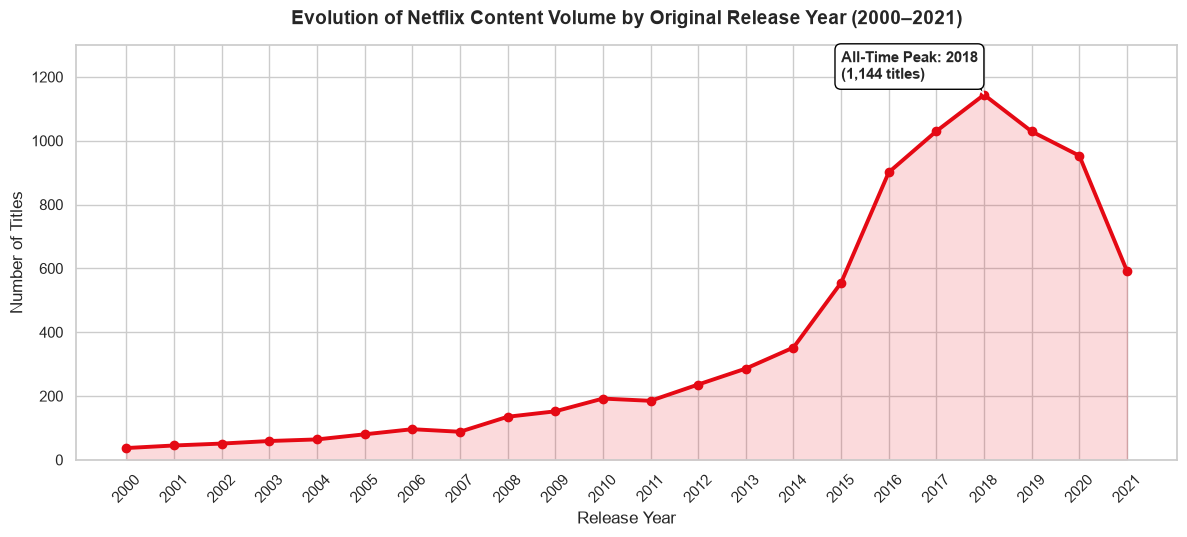

Saved yearly trend chart to: d:\AUSPIFY DATA ANALYSIS\outputs\task_4\yearly_content_releases_trend.png


In [5]:
# 1. Total Content Volume by Release Year (2000 - 2021)
plt.figure(figsize=(12, 5.5))
recent_trends = yearly_trends.loc[2000:2021]

plt.plot(recent_trends.index, recent_trends['Total'], color='#E50914', linewidth=2.8, marker='o', label='Total Titles')
plt.fill_between(recent_trends.index, recent_trends['Total'], color='#E50914', alpha=0.15)

# Annotate the peak in 2018
peak_year = 2018
peak_val = int(yearly_trends.loc[peak_year, 'Total'])
plt.annotate(f'All-Time Peak: {peak_year}\n({peak_val:,} titles)',
             xy=(peak_year, peak_val), xytext=(peak_year - 3, peak_val + 50),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=7),
             fontsize=11, fontweight='bold', bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="black", lw=1))

plt.title("Evolution of Netflix Content Volume by Original Release Year (2000–2021)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Release Year", fontsize=12)
plt.ylabel("Number of Titles", fontsize=12)
plt.xticks(recent_trends.index, rotation=45)
plt.ylim(0, 1300)
plt.tight_layout()

trend1_path = OUTPUT_DIR / 'yearly_content_releases_trend.png'
plt.savefig(trend1_path, dpi=300)
plt.show()
print(f"Saved yearly trend chart to: {trend1_path}")

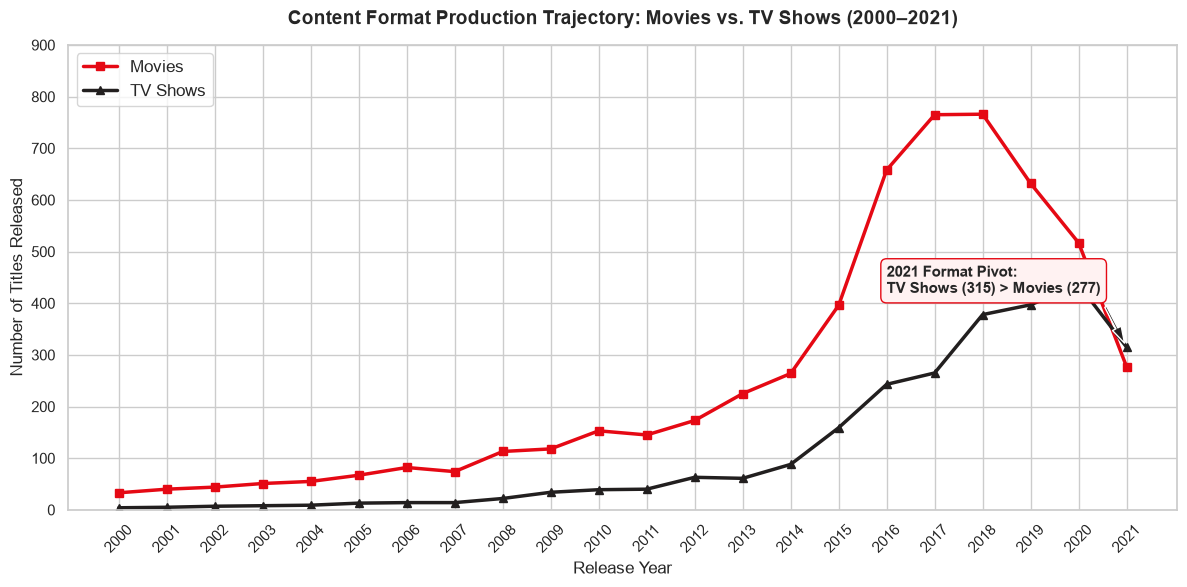

Saved format trajectory chart to: d:\AUSPIFY DATA ANALYSIS\outputs\task_4\movies_vs_tv_yearly_trend.png


In [6]:
# 2. Dual-Line Comparison: Movies vs. TV Shows Trajectory (2000 - 2021)
plt.figure(figsize=(12, 6))

plt.plot(recent_trends.index, recent_trends['Movies'], color='#E50914', linewidth=2.5, marker='s', label='Movies')
plt.plot(recent_trends.index, recent_trends['TV_Shows'], color='#221F1F', linewidth=2.5, marker='^', label='TV Shows')

# Annotate the format crossover in 2021
crossover_year = 2021
plt.annotate('2021 Format Pivot:\nTV Shows (315) > Movies (277)',
             xy=(2021, 315), xytext=(2016, 420),
             arrowprops=dict(facecolor='#221F1F', shrink=0.08, width=1.5, headwidth=7),
             fontsize=10.5, fontweight='bold', bbox=dict(boxstyle="round,pad=0.4", fc="#FFF2F2", ec="#E50914", lw=1))

plt.title("Content Format Production Trajectory: Movies vs. TV Shows (2000–2021)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Release Year", fontsize=12)
plt.ylabel("Number of Titles Released", fontsize=12)
plt.xticks(recent_trends.index, rotation=45)
plt.ylim(0, 900)
plt.legend(loc='upper left', frameon=True, fontsize=12)
plt.tight_layout()

trend2_path = OUTPUT_DIR / 'movies_vs_tv_yearly_trend.png'
plt.savefig(trend2_path, dpi=300)
plt.show()
print(f"Saved format trajectory chart to: {trend2_path}")

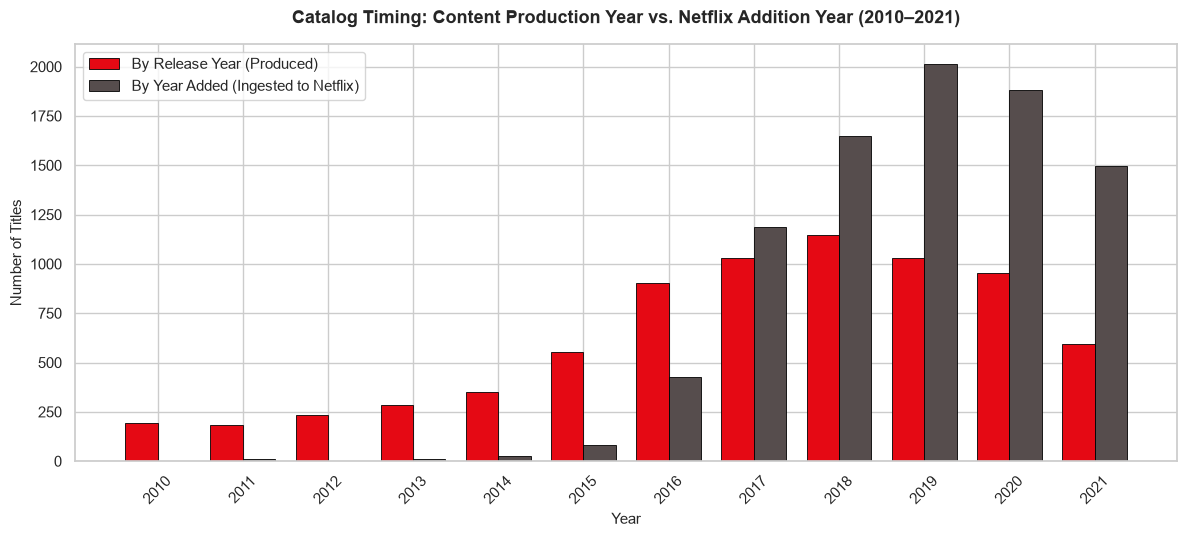

Saved ingestion comparison chart to: d:\AUSPIFY DATA ANALYSIS\outputs\task_4\release_year_vs_added_year.png


In [7]:
# 3. Release Year vs. Year Added Comparison (Ingestion Timing)
fig, ax = plt.subplots(figsize=(12, 5.5))

added_counts = df['year_added'].value_counts().sort_index()
recent_added = added_counts.loc[2010:2021]
recent_released = df[df['release_year'] >= 2010]['release_year'].value_counts().sort_index()

width = 0.38
x_indices = np.arange(len(recent_added.index))

ax.bar(x_indices - width/2, recent_released.reindex(recent_added.index).fillna(0), width=width, color='#E50914', label='By Release Year (Produced)', edgecolor='black', linewidth=0.6)
ax.bar(x_indices + width/2, recent_added.values, width=width, color='#564d4d', label='By Year Added (Ingested to Netflix)', edgecolor='black', linewidth=0.6)

ax.set_title("Catalog Timing: Content Production Year vs. Netflix Addition Year (2010–2021)", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("Number of Titles", fontsize=11)
ax.set_xticks(x_indices)
ax.set_xticklabels(recent_added.index, rotation=45)
ax.legend(loc='upper left', frameon=True, fontsize=11)
plt.tight_layout()

trend3_path = OUTPUT_DIR / 'release_year_vs_added_year.png'
plt.savefig(trend3_path, dpi=300)
plt.show()
print(f"Saved ingestion comparison chart to: {trend3_path}")

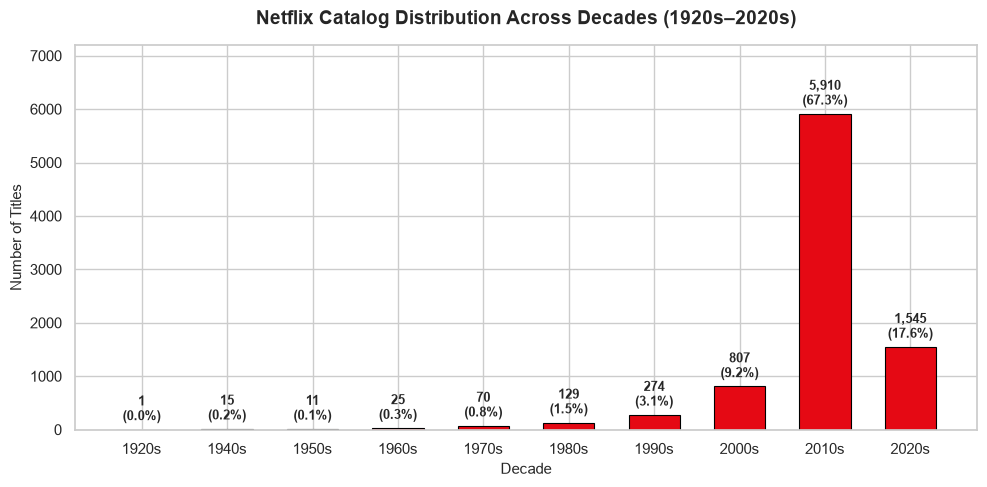

Saved decade distribution chart to: d:\AUSPIFY DATA ANALYSIS\outputs\task_4\decade_wise_distribution.png


In [8]:
# 4. Decade-Wise Content Distribution
plt.figure(figsize=(10, 5))
decades_order = ['1920s', '1940s', '1950s', '1960s', '1970s', '1980s', '1990s', '2000s', '2010s', '2020s']
decades_filtered = decade_summary.reindex([d for d in decades_order if d in decade_summary.index])

bars = plt.bar(decades_filtered.index, decades_filtered['Total'], color='#E50914', edgecolor='black', linewidth=0.8, width=0.6)

for bar in bars:
    yval = bar.get_height()
    pct = (yval / len(df)) * 100
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 100, f"{int(yval):,}\n({pct:.1f}%)", ha='center', va='bottom', fontsize=9.5, fontweight='bold')

plt.title("Netflix Catalog Distribution Across Decades (1920s–2020s)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Decade", fontsize=11)
plt.ylabel("Number of Titles", fontsize=11)
plt.ylim(0, 7200)
plt.tight_layout()

trend4_path = OUTPUT_DIR / 'decade_wise_distribution.png'
plt.savefig(trend4_path, dpi=300)
plt.show()
print(f"Saved decade distribution chart to: {trend4_path}")

## 7. Step 5: Interpretation of Business Patterns & Analytical Limitations

### Key Business Insights:
1. **The Modernity of Netflix's Catalog:** An astonishing **82.9% of all titles (7,285 titles)** were released between **2010 and 2021**. Netflix is definitively a modern-content platform, not an archival repository.
2. **The 2018 Peak & Market Saturation:** Content volume peaked in 2018 with 1,144 titles. The slight deceleration in 2019–2020 reflects a strategic shift from pure volume acquisition to curated quality and high-production-value original tentpoles.
3. **The Episodic Format Pivot:** TV Shows expanded continuously as a percentage of new content, ultimately overtaking Movies in 2021 (**53.2% TV Shows vs. 46.8% Movies**). Series drive subscriber habituation and recurring monthly retention.
4. **COVID-19 Production Halts & Data Cutoff:** The 2021 volume dip (592 titles) reflects two complementary factors:
   - The dataset ends in **September 2021** (incomplete fourth-quarter data).
   - Global Hollywood and international production shutdowns throughout 2020 delayed release schedules well into late 2021.

### Data Limitations:
- The dataset lacks viewer engagement statistics (e.g., total hours watched, completion rates).
- Date added records begin in 2008, meaning titles added in Netflix's earliest streaming infancy are sparse.

### Conclusion:
Task 4 is complete. The temporal evolution of Netflix's catalog and its decisive pivot toward TV shows are documented and exported to `outputs/task_4/`. We proceed to Task 5 (Rating and Genre Analysis).